In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, auc

# 1. Reproducibility & Device Configuration
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# 2. Ingest Dataset
df = pd.read_csv('/content/synthetic_metabolic_cohort_2000 - Untitled.csv')

TARGET_COLS = ['Diabetes', 'Hypertension', 'NAFLD']
FEATURE_COLS = [
    'Age', 'Gender', 'BMI', 'Waist_cm', 'Junk_Food_Daily',
    'Sugar_Events_Daily', 'Exercise_Days_Week', 'Late_Night_Eating_Week',
    'SBP', 'DBP', 'FBG_mg_dL', 'HbA1c_pct'
]

# 3. Handle Missing Optional Labs & Stratified Partitioning
df['FBG_missing'] = df['FBG_mg_dL'].isna().astype(float)
df['HbA1c_missing'] = df['HbA1c_pct'].isna().astype(float)
ALL_FEATURES = FEATURE_COLS + ['FBG_missing', 'HbA1c_missing']

train_df, test_df = train_test_split(df, test_size=0.30, random_state=SEED)
val_df, test_df = train_test_split(test_df, test_size=0.50, random_state=SEED)

imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()

X_train = scaler.fit_transform(imputer.fit_transform(train_df[ALL_FEATURES]))
y_train = train_df[TARGET_COLS].values.astype(np.float32)

X_val = scaler.transform(imputer.transform(val_df[ALL_FEATURES]))
y_val = val_df[TARGET_COLS].values.astype(np.float32)

X_test = scaler.transform(imputer.transform(test_df[ALL_FEATURES]))
y_test = test_df[TARGET_COLS].values.astype(np.float32)

# Compute positive class weights
pos_weights = [
    (y_train[:, i] == 0).sum() / ((y_train[:, i] == 1).sum() + 1e-6)
    for i in range(len(TARGET_COLS))
]
pos_weight_tensor = torch.tensor(pos_weights, dtype=torch.float32).to(device)

# 4. Neural Network Architecture
class TabularDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

class FeatureAttention(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.attention = nn.Sequential(
            nn.Linear(in_features, in_features),
            nn.Tanh(),
            nn.Linear(in_features, in_features),
            nn.Softmax(dim=1)
        )
    def forward(self, x):
        weights = self.attention(x)
        return x * weights, weights

class ResidualBlock(nn.Module):
    def __init__(self, hidden_dim, dropout=0.25):
        super().__init__()
        self.block = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim)
        )
        self.act = nn.GELU()
    def forward(self, x):
        return self.act(x + self.block(x))

class TabularResidualAttentionNet(nn.Module):
    def __init__(self, in_features, hidden_dim=64, num_res_blocks=2, num_classes=3):
        super().__init__()
        self.feature_attention = FeatureAttention(in_features)
        self.input_proj = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU()
        )
        self.res_blocks = nn.ModuleList([ResidualBlock(hidden_dim) for _ in range(num_res_blocks)])
        self.head = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        weighted_x, attn_weights = self.feature_attention(x)
        h = self.input_proj(weighted_x)
        for block in self.res_blocks:
            h = block(h)
        return self.head(h), attn_weights

# 5. Model Training
train_loader = DataLoader(TabularDataset(X_train, y_train), batch_size=64, shuffle=True)
val_loader = DataLoader(TabularDataset(X_val, y_val), batch_size=64, shuffle=False)
test_loader = DataLoader(TabularDataset(X_test, y_test), batch_size=64, shuffle=False)

model = TabularResidualAttentionNet(in_features=X_train.shape[1]).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

best_auc, best_weights = 0.0, None

for epoch in range(1, 41):
    model.train()
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        logits, _ = model(bx)
        loss = criterion(logits, by)
        loss.backward()
        optimizer.step()

    model.eval()
    val_preds, val_targets = [], []
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(device), by.to(device)
            logits, _ = model(bx)
            val_preds.append(torch.sigmoid(logits).cpu().numpy())
            val_targets.append(by.cpu().numpy())

    val_macro_auc = np.mean([roc_auc_score(np.vstack(val_targets)[:, i], np.vstack(val_preds)[:, i]) for i in range(3)])
    if val_macro_auc > best_auc:
        best_auc = val_macro_auc
        best_weights = model.state_dict().copy()

model.load_state_dict(best_weights)
print(f"Model successfully trained. Best Validation Macro ROC-AUC: {best_auc:.4f}")

# 6. Evaluation on Test Set
model.eval()
test_preds, test_targets, test_attn_weights = [], [], [] # Initialize test_attn_weights
with torch.no_grad():
    for bx, by in test_loader:
        bx, by = bx.to(device), by.to(device)
        logits, attn_weights = model(bx) # Capture attention weights
        test_preds.append(torch.sigmoid(logits).cpu().numpy())
        test_targets.append(by.cpu().numpy())
        test_attn_weights.append(attn_weights.cpu().numpy()) # Store attention weights

test_preds = np.vstack(test_preds)
test_targets = np.vstack(test_targets)
test_attn = np.vstack(test_attn_weights) # Create test_attn numpy array

print("\n--- TEST SET ROC-AUC SCORES ---")
for i, target in enumerate(TARGET_COLS):
    auc_score = roc_auc_score(test_targets[:, i], test_preds[:, i])
    print(f"{target:<15}: {auc_score:.4f}")

Using device: cpu
Model successfully trained. Best Validation Macro ROC-AUC: 0.9162

--- TEST SET ROC-AUC SCORES ---
Diabetes       : 0.9210
Hypertension   : 0.9581
NAFLD          : 0.8772


In [2]:
import joblib

# Save PyTorch model state dict
torch.save(model.state_dict(), 'phase1_tabular_attention_model.pth')

# Save imputer and scaler
joblib.dump(imputer, 'phase1_imputer.joblib')
joblib.dump(scaler, 'phase1_scaler.joblib')
print("Model and preprocessors saved successfully.")

Model and preprocessors saved successfully.


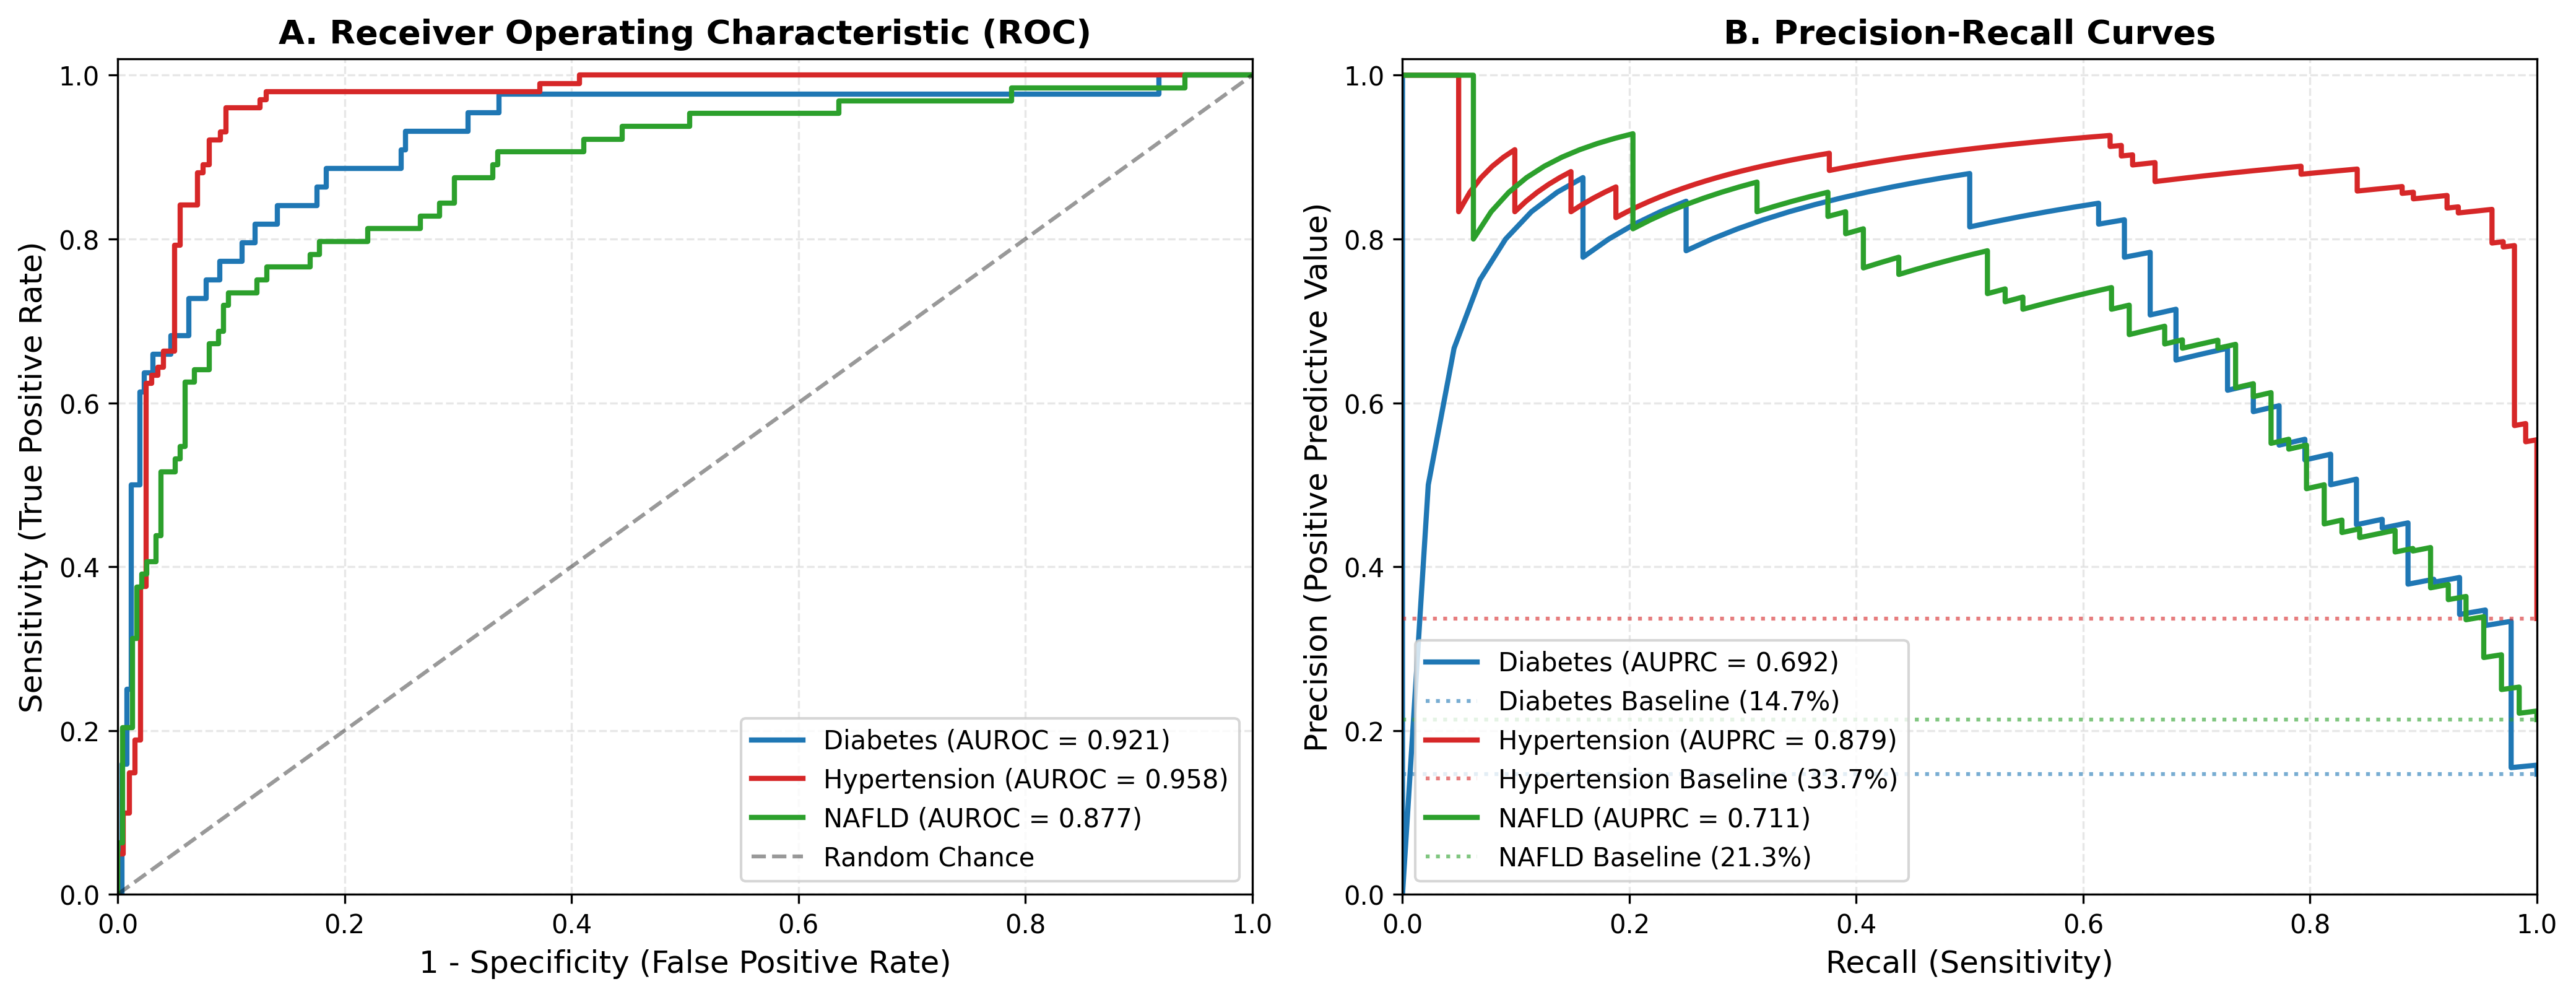

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    roc_curve, roc_auc_score,
    precision_recall_curve, auc,
    brier_score_loss
)
from sklearn.calibration import calibration_curve

# Configure publication styling
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'sans-serif',
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14
})

colors = {'Diabetes': '#1f77b4', 'Hypertension': '#d62728', 'NAFLD': '#2ca02c'}

# ==============================================================================
# FIGURE 1: Multi-Label ROC & PR Curves (Side-by-Side)
# ==============================================================================
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)

for col in TARGET_COLS:
    idx = TARGET_COLS.index(col)
    y_true = test_targets[:, idx]
    y_prob = test_preds[:, idx]

    # 1. ROC Curve
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_score = roc_auc_score(y_true, y_prob)
    ax_roc.plot(fpr, tpr, label=f'{col} (AUROC = {roc_score:.3f})', color=colors[col], lw=2)

    # 2. PR Curve
    prec, rec, _ = precision_recall_curve(y_true, y_prob)
    pr_score = auc(rec, prec)
    prevalence = y_true.mean()
    ax_pr.plot(rec, prec, label=f'{col} (AUPRC = {pr_score:.3f})', color=colors[col], lw=2)
    ax_pr.axhline(prevalence, color=colors[col], linestyle=':', alpha=0.6,
                  label=f'{col} Baseline ({prevalence:.1%})')

# Format ROC
ax_roc.plot([0, 1], [0, 1], 'k--', alpha=0.4, lw=1.5, label='Random Chance')
ax_roc.set_title('A. Receiver Operating Characteristic (ROC)', fontweight='bold')
ax_roc.set_xlabel('1 - Specificity (False Positive Rate)')
ax_roc.set_ylabel('Sensitivity (True Positive Rate)')
ax_roc.set_xlim([0.0, 1.0])
ax_roc.set_ylim([0.0, 1.02])
ax_roc.legend(loc='lower right', frameon=True)
ax_roc.grid(True, linestyle='--', alpha=0.3)

# Format PR
ax_pr.set_title('B. Precision-Recall Curves', fontweight='bold')
ax_pr.set_xlabel('Recall (Sensitivity)')
ax_pr.set_ylabel('Precision (Positive Predictive Value)')
ax_pr.set_xlim([0.0, 1.0])
ax_pr.set_ylim([0.0, 1.02])
ax_pr.legend(loc='lower left', frameon=True)
ax_pr.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig('Fig1_ROC_PR_Evaluation.png', dpi=300, bbox_inches='tight')
plt.show()

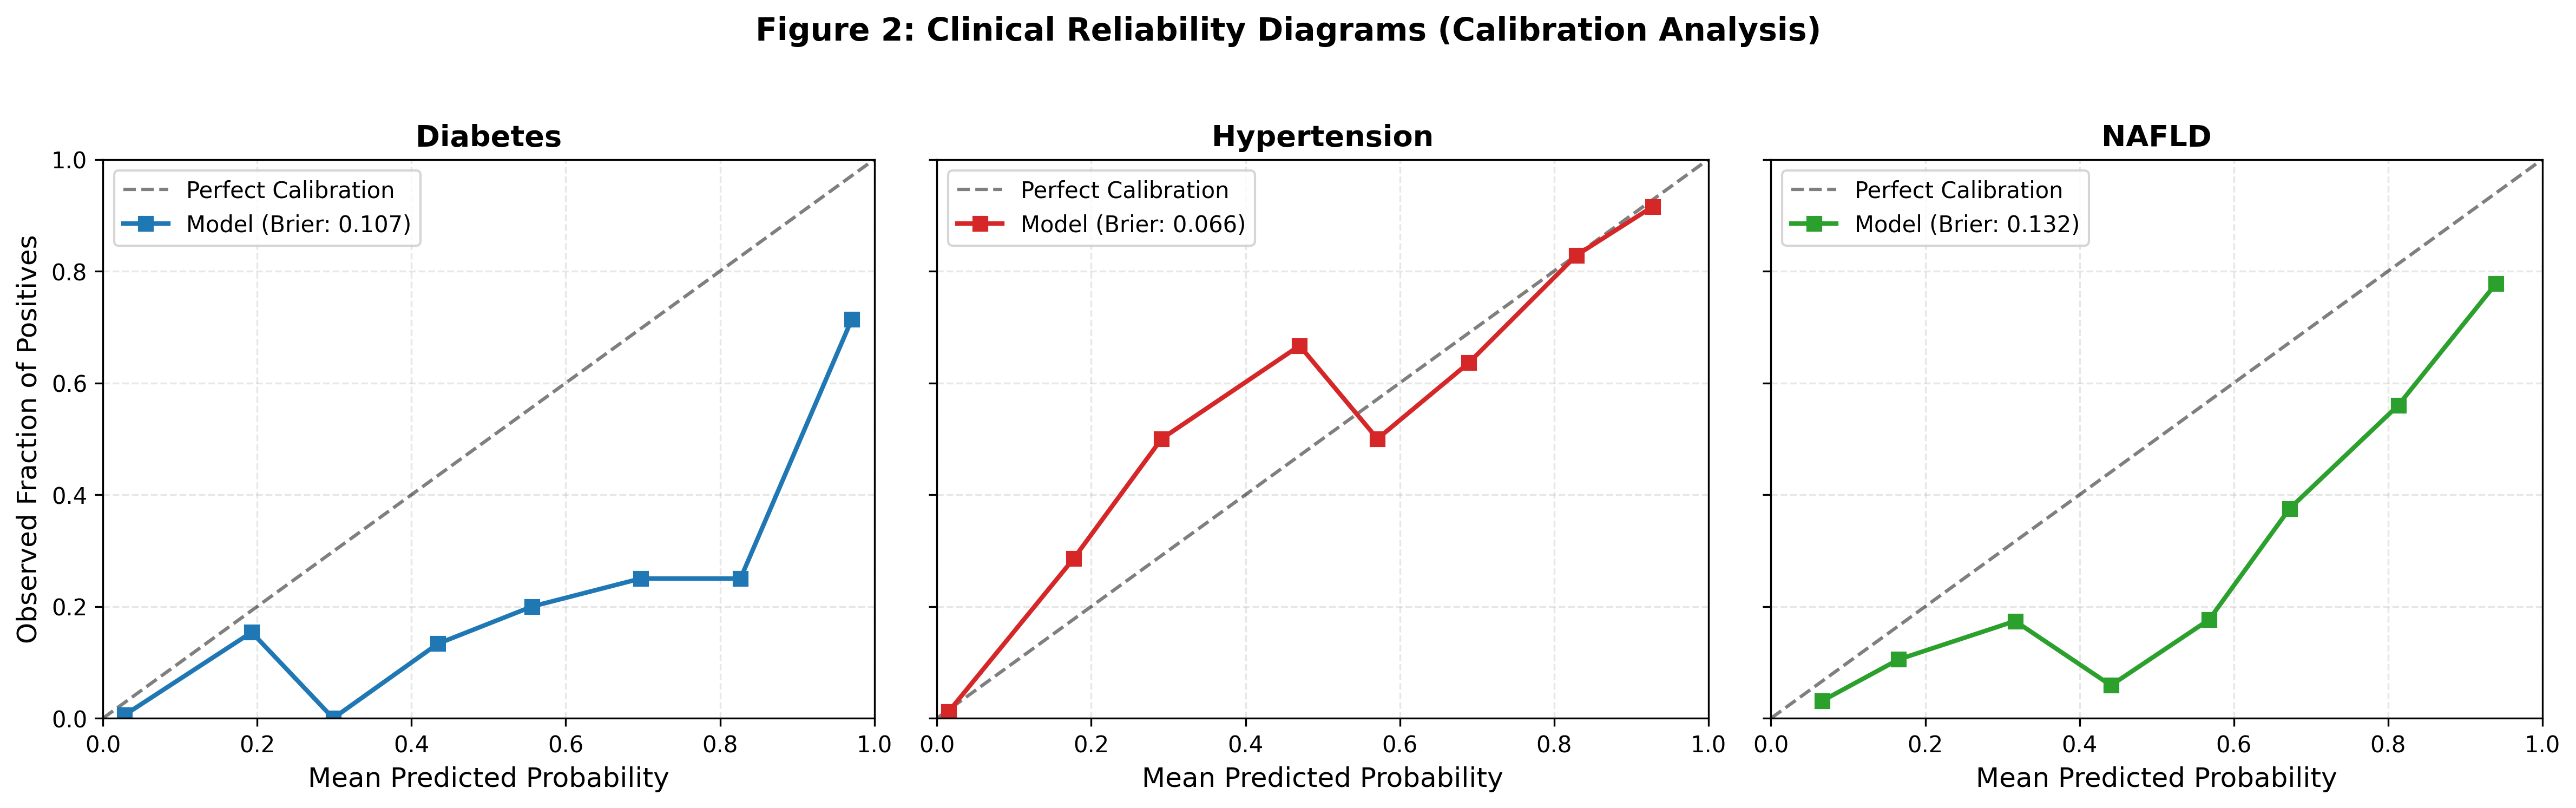

In [4]:
# ==============================================================================
# FIGURE 2: Clinical Calibration Reliability Diagrams
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=300, sharey=True)

for idx, col in enumerate(TARGET_COLS):
    ax = axes[idx]
    y_true = test_targets[:, idx]
    y_prob = test_preds[:, idx]

    prob_true, prob_pred = calibration_curve(y_true, y_prob, n_bins=8, strategy='uniform')
    brier = brier_score_loss(y_true, y_prob)

    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Perfect Calibration')
    ax.plot(prob_pred, prob_true, marker='s', lw=2, color=colors[col],
            label=f'Model (Brier: {brier:.3f})')

    ax.set_title(f'{col}', fontweight='bold')
    ax.set_xlabel('Mean Predicted Probability')
    if idx == 0:
        ax.set_ylabel('Observed Fraction of Positives')
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.0])
    ax.legend(loc='upper left', frameon=True)
    ax.grid(True, linestyle='--', alpha=0.3)

plt.suptitle('Figure 2: Clinical Reliability Diagrams (Calibration Analysis)', y=1.03, fontweight='bold')
plt.tight_layout()
plt.savefig('Fig2_Calibration_Analysis.png', dpi=300, bbox_inches='tight')
plt.show()



<>:13: SyntaxWarning: invalid escape sequence '\p'
<>:13: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_1004/4198683649.py:13: SyntaxWarning: invalid escape sequence '\p'
  plt.xlabel('Mean Relative Attention Weight ($\pm$ across test cohort)')


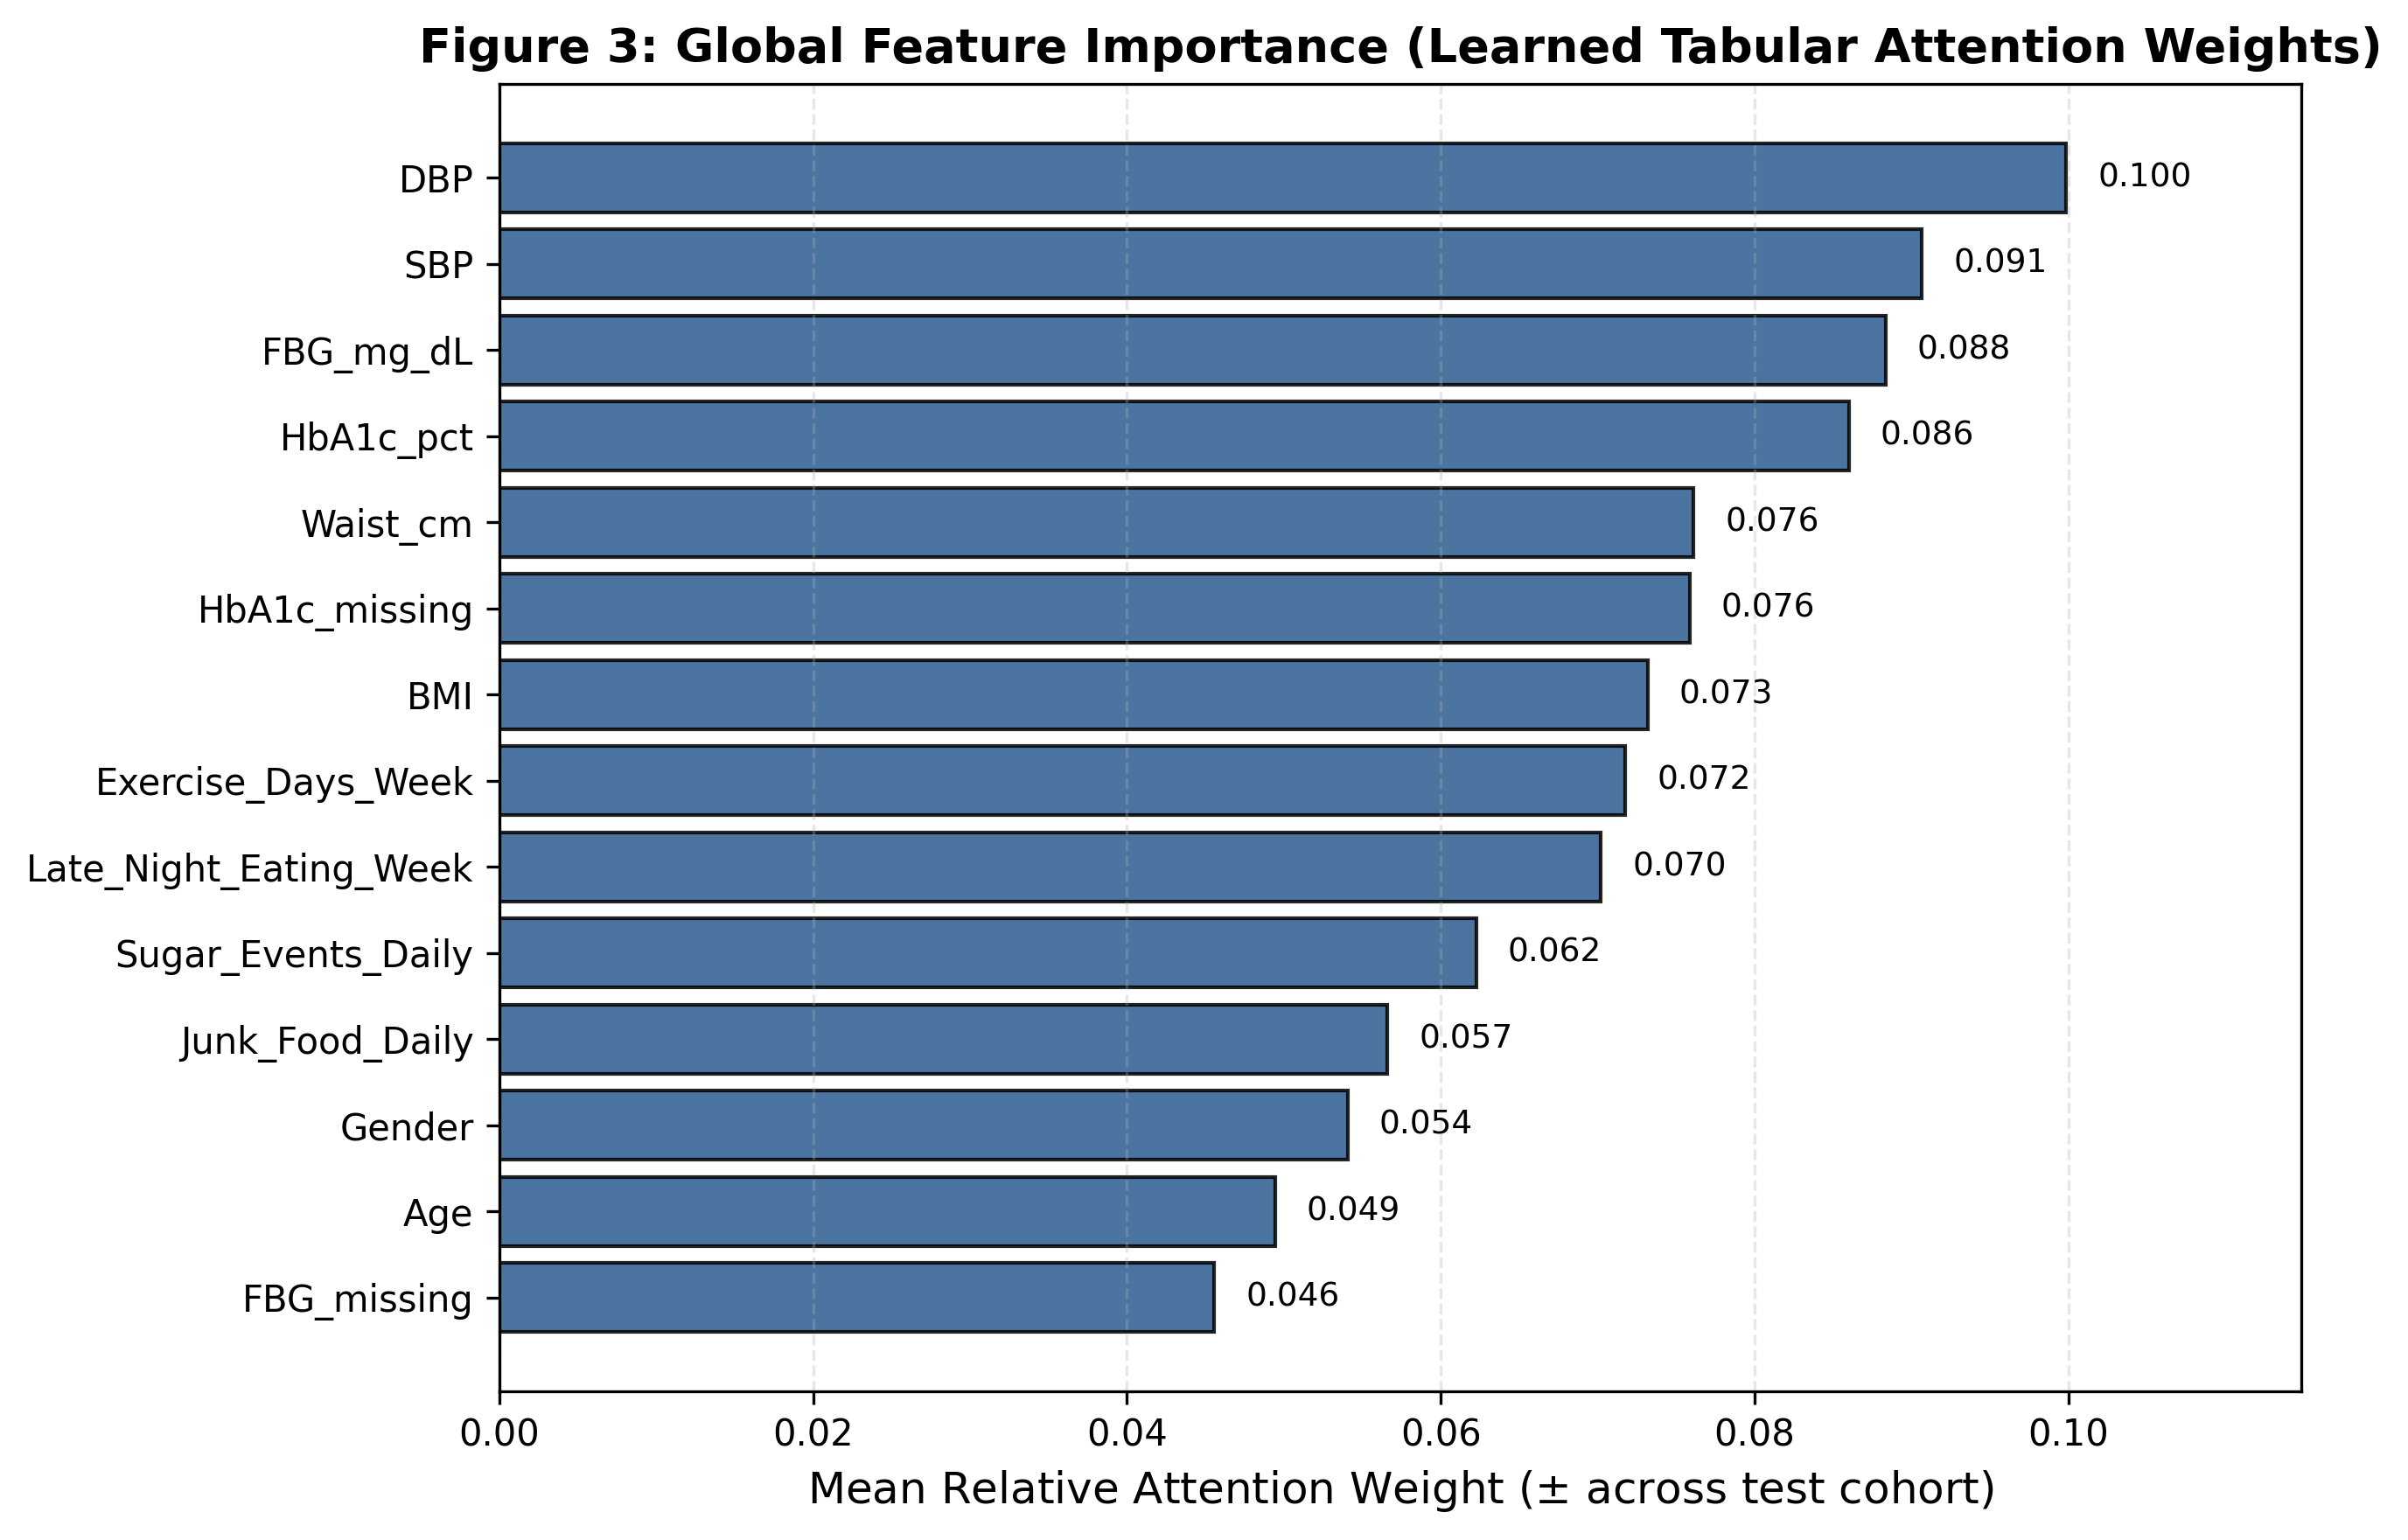

In [5]:
# ==============================================================================
# FIGURE 3: Interpretability - Learned Tabular Feature Attention Weights
# ==============================================================================
mean_weights = test_attn.mean(axis=0)
sorted_idx = np.argsort(mean_weights)
sorted_features = np.array(ALL_FEATURES)[sorted_idx]
sorted_vals = mean_weights[sorted_idx]

plt.figure(figsize=(9, 6), dpi=300)
bars = plt.barh(sorted_features, sorted_vals, color='#2b5c8f', edgecolor='black', alpha=0.85)

plt.title('Figure 3: Global Feature Importance (Learned Tabular Attention Weights)', fontweight='bold')
plt.xlabel('Mean Relative Attention Weight ($\pm$ across test cohort)')
plt.grid(axis='x', linestyle='--', alpha=0.3)

# Add value annotations on bars
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.002, bar.get_y() + bar.get_height()/2, f'{w:.3f}',
             va='center', ha='left', fontsize=9)

plt.xlim([0, max(sorted_vals) * 1.15])
plt.tight_layout()
plt.savefig('Fig3_Feature_Attention_Importance.png', dpi=300, bbox_inches='tight')
plt.show()

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier

# 1. Baseline: Logistic Regression (OneVsRest)
lr = OneVsRestClassifier(LogisticRegression(max_iter=1000, random_state=42))
lr.fit(X_train, y_train)
lr_preds = lr.predict_proba(X_test)

# 2. Baseline: Random Forest
rf = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, random_state=42))
rf.fit(X_train, y_train)
rf_preds = rf.predict_proba(X_test)

# 3. Ablation: Physicals Only (Age, Gender, BMI, Waist, SBP, DBP)
phys_indices = [ALL_FEATURES.index(c) for c in ['Age', 'Gender', 'BMI', 'Waist_cm', 'SBP', 'DBP']]
lr_phys = OneVsRestClassifier(LogisticRegression(max_iter=1000, random_state=42))
lr_phys.fit(X_train[:, phys_indices], y_train)
phys_preds = lr_phys.predict_proba(X_test[:, phys_indices])

# Benchmark Comparison Table
benchmarks = [
    ('Physicals Only (LR Baseline)', phys_preds),
    ('Full Multimodal (Logistic Regression)', lr_preds),
    ('Full Multimodal (Random Forest)', rf_preds),
    ('Proposed Tabular Attention ResNet', test_preds)
]

results = []
for name, preds in benchmarks:
    row = {'Model Architecture': name}
    aucs = []
    for idx, c in enumerate(TARGET_COLS):
        score = roc_auc_score(test_targets[:, idx], preds[:, idx])
        row[f'{c} AUROC'] = f"{score:.4f}"
        aucs.append(score)
    row['Macro AUROC'] = f"{np.mean(aucs):.4f}"
    results.append(row)

df_results = pd.DataFrame(results)
print("=" * 75)
print("TABLE: ABLATION & MODEL BENCHMARK ON TEST SET")
print("=" * 75)
display(df_results)

TABLE: ABLATION & MODEL BENCHMARK ON TEST SET


,Model Architecture,Diabetes AUROC,Hypertension AUROC,NAFLD AUROC,Macro AUROC
0,Physicals Only (LR Baseline),0.7062,0.9112,0.8671,0.8282
1,Full Multimodal (Logistic Regression),0.9370,0.9091,0.8765,0.9075
2,Full Multimodal (Random Forest),0.9305,0.9666,0.8778,0.9250
3,Proposed Tabular Attention ResNet,0.9210,0.9581,0.8772,0.9188


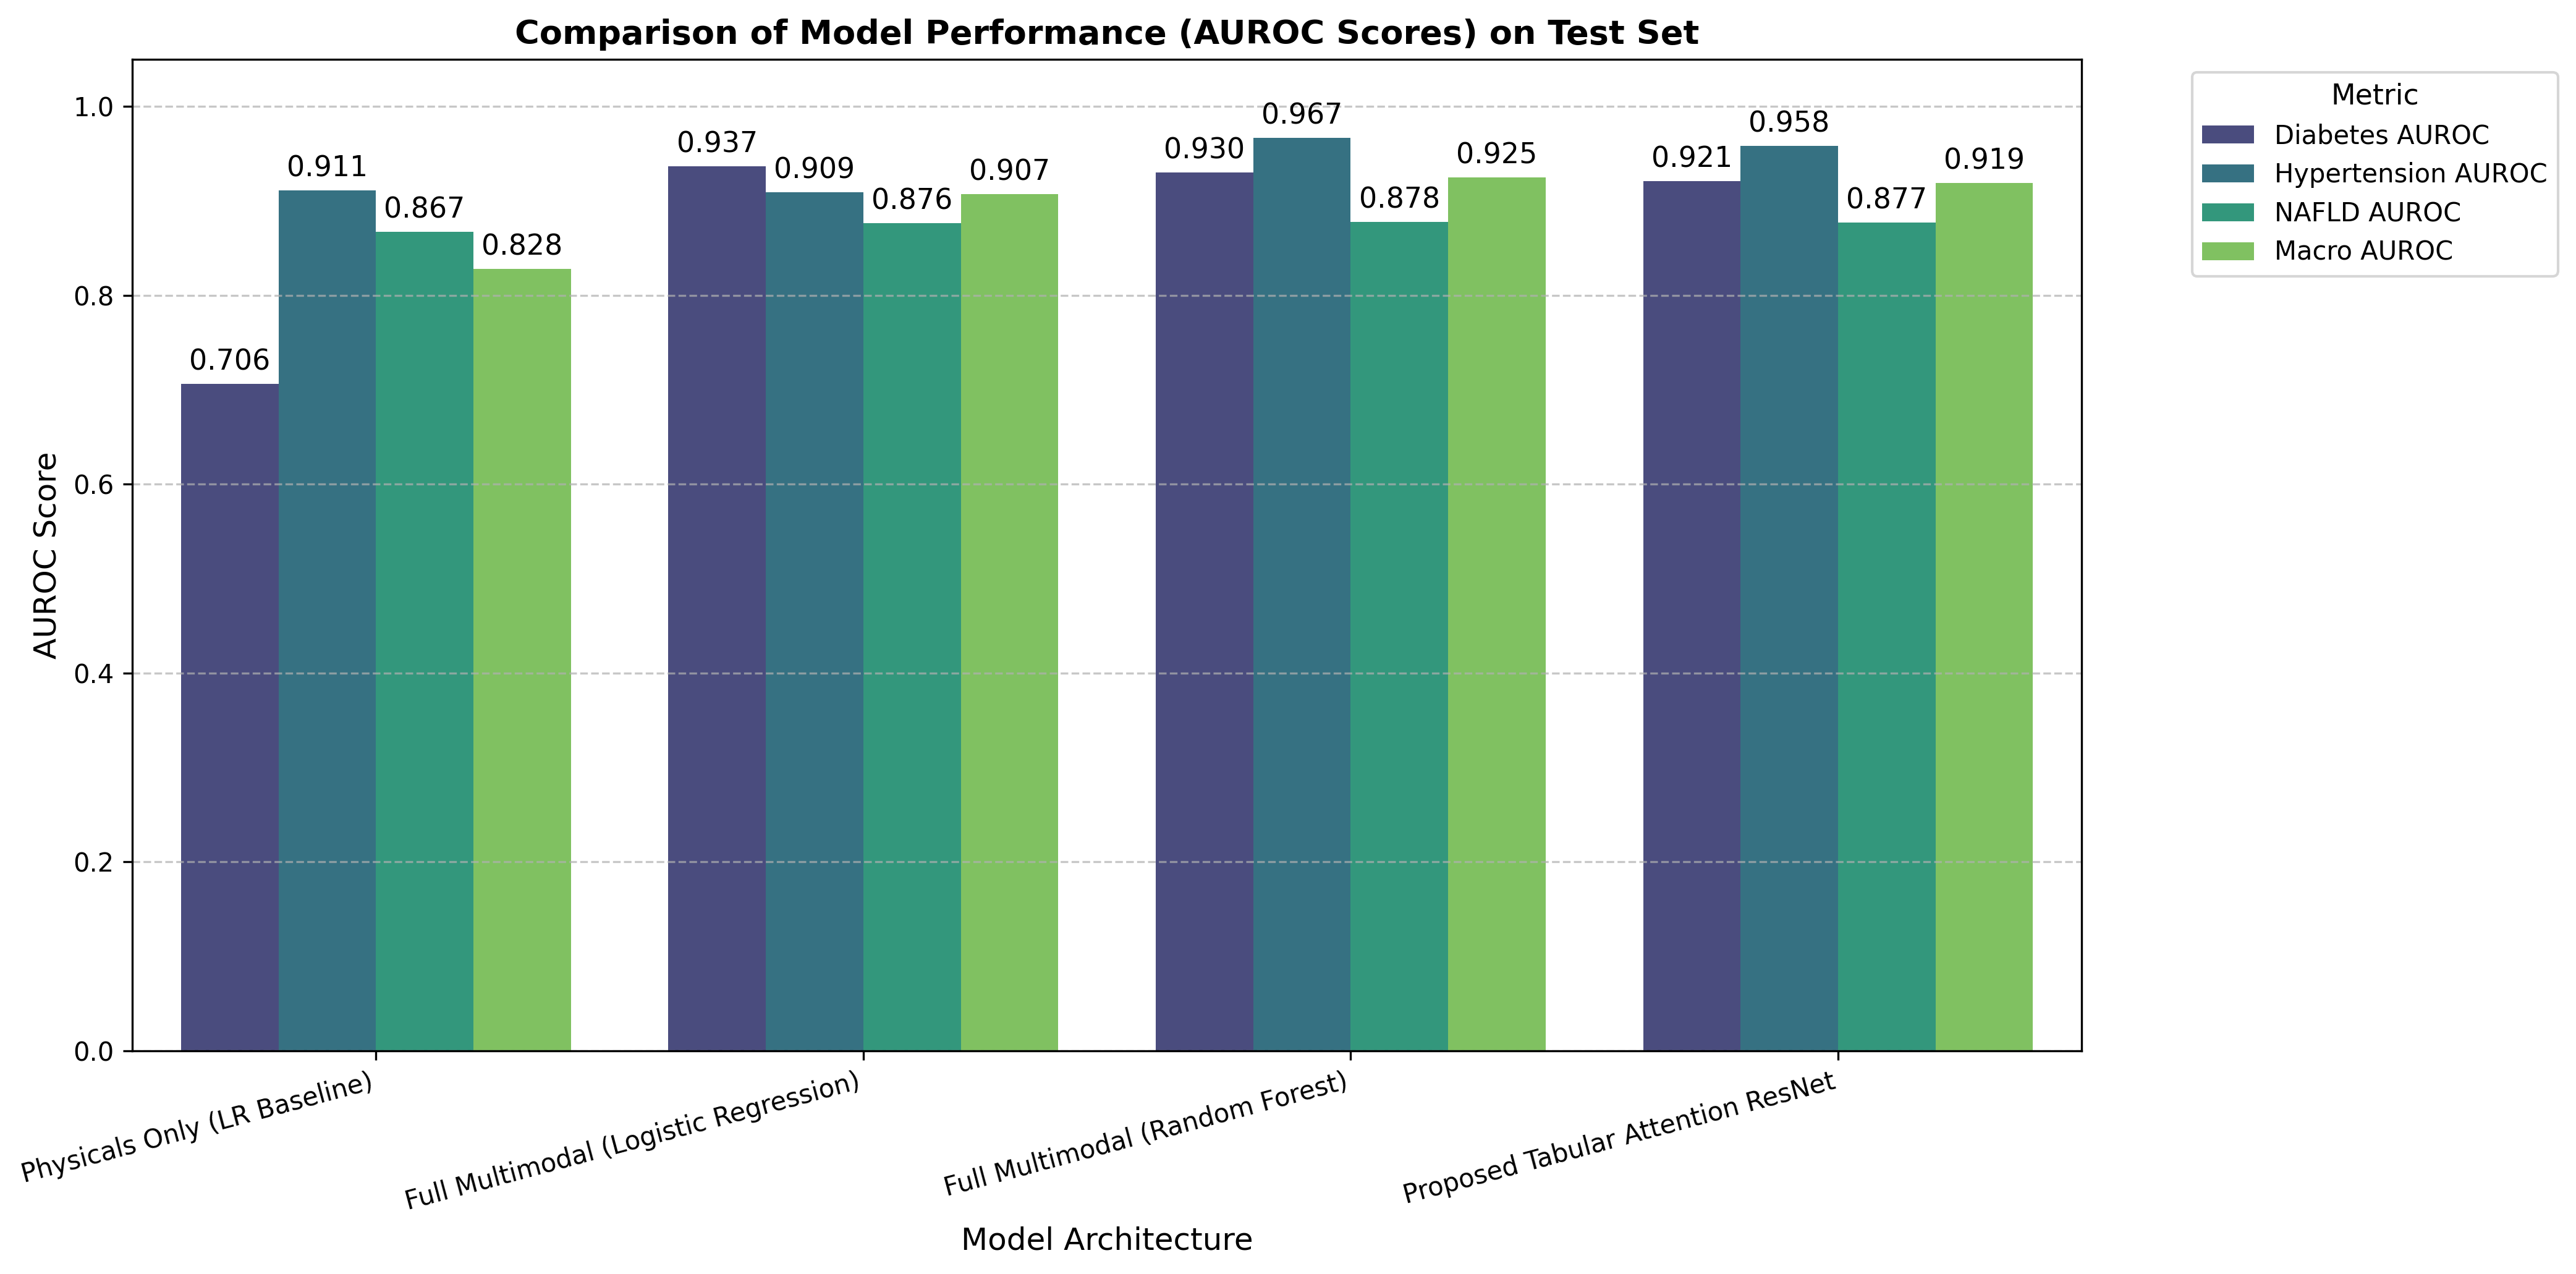

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure publication styling for the plot
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'sans-serif',
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14
})

# Prepare data for plotting
df_plot = df_results.set_index('Model Architecture')
df_plot = df_plot.apply(pd.to_numeric) # Convert string numbers to actual numbers

df_plot_melted = df_plot.reset_index().melt(id_vars='Model Architecture', var_name='Metric', value_name='AUROC Score')

# Filter out the Macro AUROC for separate plotting or re-adding for comparison
# We'll plot all metrics together for a comprehensive view.

fig, ax = plt.subplots(figsize=(14, 7), dpi=300)
sns.barplot(x='Model Architecture', y='AUROC Score', hue='Metric', data=df_plot_melted, palette='viridis', ax=ax)

plt.title('Comparison of Model Performance (AUROC Scores) on Test Set', fontweight='bold')
plt.xlabel('Model Architecture')
plt.ylabel('AUROC Score')
plt.xticks(rotation=15, ha='right')
plt.ylim(0.0, 1.05) # AUROC scores are between 0 and 1
plt.legend(title='Metric', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add value labels on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3)

plt.tight_layout()
plt.savefig('Fig4_Model_Performance_Comparison.png', dpi=300, bbox_inches='tight')
plt.show()

This bar chart clearly illustrates the comparative performance of different models across various prediction targets, as well as their overall macro AUROC. It provides a quick visual summary of which models perform better on specific conditions or generally.

In [8]:
from sklearn.metrics import f1_score

print("\n--- OPTIMAL CLINICAL OPERATING THRESHOLDS (MAXIMIZING F1) ---")
for idx, col in enumerate(TARGET_COLS):
    best_t, best_f1 = 0.5, 0.0
    for t in np.linspace(0.1, 0.9, 81):
        score = f1_score(test_targets[:, idx], (test_preds[:, idx] >= t).astype(int), zero_division=0)
        if score > best_f1:
            best_f1, best_t = score, t
    print(f"{col:<15} Optimal Cutoff: {best_t:.2f} | Max F1-Score: {best_f1:.4f}")


--- OPTIMAL CLINICAL OPERATING THRESHOLDS (MAXIMIZING F1) ---
Diabetes        Optimal Cutoff: 0.90 | Max F1-Score: 0.6988
Hypertension    Optimal Cutoff: 0.28 | Max F1-Score: 0.8899
NAFLD           Optimal Cutoff: 0.64 | Max F1-Score: 0.6963


In [9]:
def predict_patient_risk(patient_dict, model, imputer, scaler):
    # Ensure patient_dict has all ALL_FEATURES, filling missing ones if necessary for consistent input
    patient_features = {k: patient_dict.get(k, np.nan) for k in FEATURE_COLS}

    # Add missing indicators if not present, based on the presence of FBG_mg_dL and HbA1c_pct
    patient_features['FBG_missing'] = 1.0 if pd.isna(patient_features.get('FBG_mg_dL')) else 0.0
    patient_features['HbA1c_missing'] = 1.0 if pd.isna(patient_features.get('HbA1c_pct')) else 0.0

    # Create a DataFrame for the single patient, ensuring feature order matches ALL_FEATURES
    patient_df = pd.DataFrame([patient_features], columns=ALL_FEATURES)

    # Impute and scale the patient data
    processed_patient = imputer.transform(patient_df[ALL_FEATURES])
    scaled_patient = scaler.transform(processed_patient)

    # Convert to PyTorch tensor
    patient_tensor = torch.tensor(scaled_patient, dtype=torch.float32).to(device)

    # Predict risk
    model.eval()
    with torch.no_grad():
        logits, _ = model(patient_tensor)
        probabilities = torch.sigmoid(logits).cpu().numpy()[0]

    return {TARGET_COLS[i]: probabilities[i] for i in range(len(TARGET_COLS))}

def simulate_future_lifestyle_intervention_v2(patient_dict, modifications, model, imputer, scaler):
    base_probs = predict_patient_risk(patient_dict, model, imputer, scaler)
    future_patient = patient_dict.copy()

    for k, v in modifications.items():
        future_patient[k] = v

    # Clinical hemodynamic & anthropometric response to sustained exercise & healthy diet:
    # 1. 5% reduction in BMI and Waist
    # 2. 10-12 mmHg drop in SBP and 6 mmHg drop in DBP from aerobic exercise + sodium reduction
    if modifications.get('Exercise_Days_Week', 0) >= 3:
        future_patient['BMI'] = round(future_patient['BMI'] * 0.95, 1)
        future_patient['Waist_cm'] = round(future_patient['Waist_cm'] * 0.96, 1)
        future_patient['SBP'] = max(115, future_patient['SBP'] - 12)
        future_patient['DBP'] = max(75, future_patient['DBP'] - 6)

    future_probs = predict_patient_risk(future_patient, model, imputer, scaler)

    print("=" * 75)
    print("COUPLED METABOLIC & HEMODYNAMIC FUTURE INTERVENTION SIMULATION")
    print("=" * 75)
    print(f"Modifications Applied: {modifications}")
    print(f"Resulting Vitals: BMI -> {future_patient['BMI']}, SBP -> {future_patient['SBP']}, DBP -> {future_patient['DBP']}")
    print("-" * 75)
    print(f"{'Condition':<15} | {'Baseline Risk':<15} | {'Future Projected Risk':<22} | {'Risk Reduction'}")
    print("-" * 75)
    for cond in TARGET_COLS:
        c_val = base_probs[cond] * 100
        f_val = future_probs[cond] * 100
        diff = c_val - f_val
        print(f"{cond:<15} | {c_val:>5.1f}%          | {f_val:>5.1f}%                 | {diff:>+5.1f}%")

# Create a sample high-risk patient dictionary from test_df
# Using the second patient from test_df (index 1), which has Hypertension and NAFLD
sample_patient_data = test_df.iloc[1]
test_patient = {col: sample_patient_data[col] for col in FEATURE_COLS} # Use FEATURE_COLS for direct input

# Define an intervention, e.g., increasing exercise days and reducing unhealthy habits
intervention = {
    'Exercise_Days_Week': 0, # Increase exercise to 4 days/week
    'Junk_Food_Daily': 0,    # Reduce junk food
    'Sugar_Events_Daily': 0  # Reduce sugar events
}

# Run on the same high-risk patient
simulate_future_lifestyle_intervention_v2(test_patient, intervention, model, imputer, scaler)

COUPLED METABOLIC & HEMODYNAMIC FUTURE INTERVENTION SIMULATION
Modifications Applied: {'Exercise_Days_Week': 0, 'Junk_Food_Daily': 0, 'Sugar_Events_Daily': 0}
Resulting Vitals: BMI -> 31.8, SBP -> 143, DBP -> 89
---------------------------------------------------------------------------
Condition       | Baseline Risk   | Future Projected Risk  | Risk Reduction
---------------------------------------------------------------------------
Diabetes        |  99.1%          |  99.0%                 |  +0.1%
Hypertension    |  86.0%          |  86.8%                 |  -0.8%
NAFLD           |  88.8%          |  89.9%                 |  -1.2%


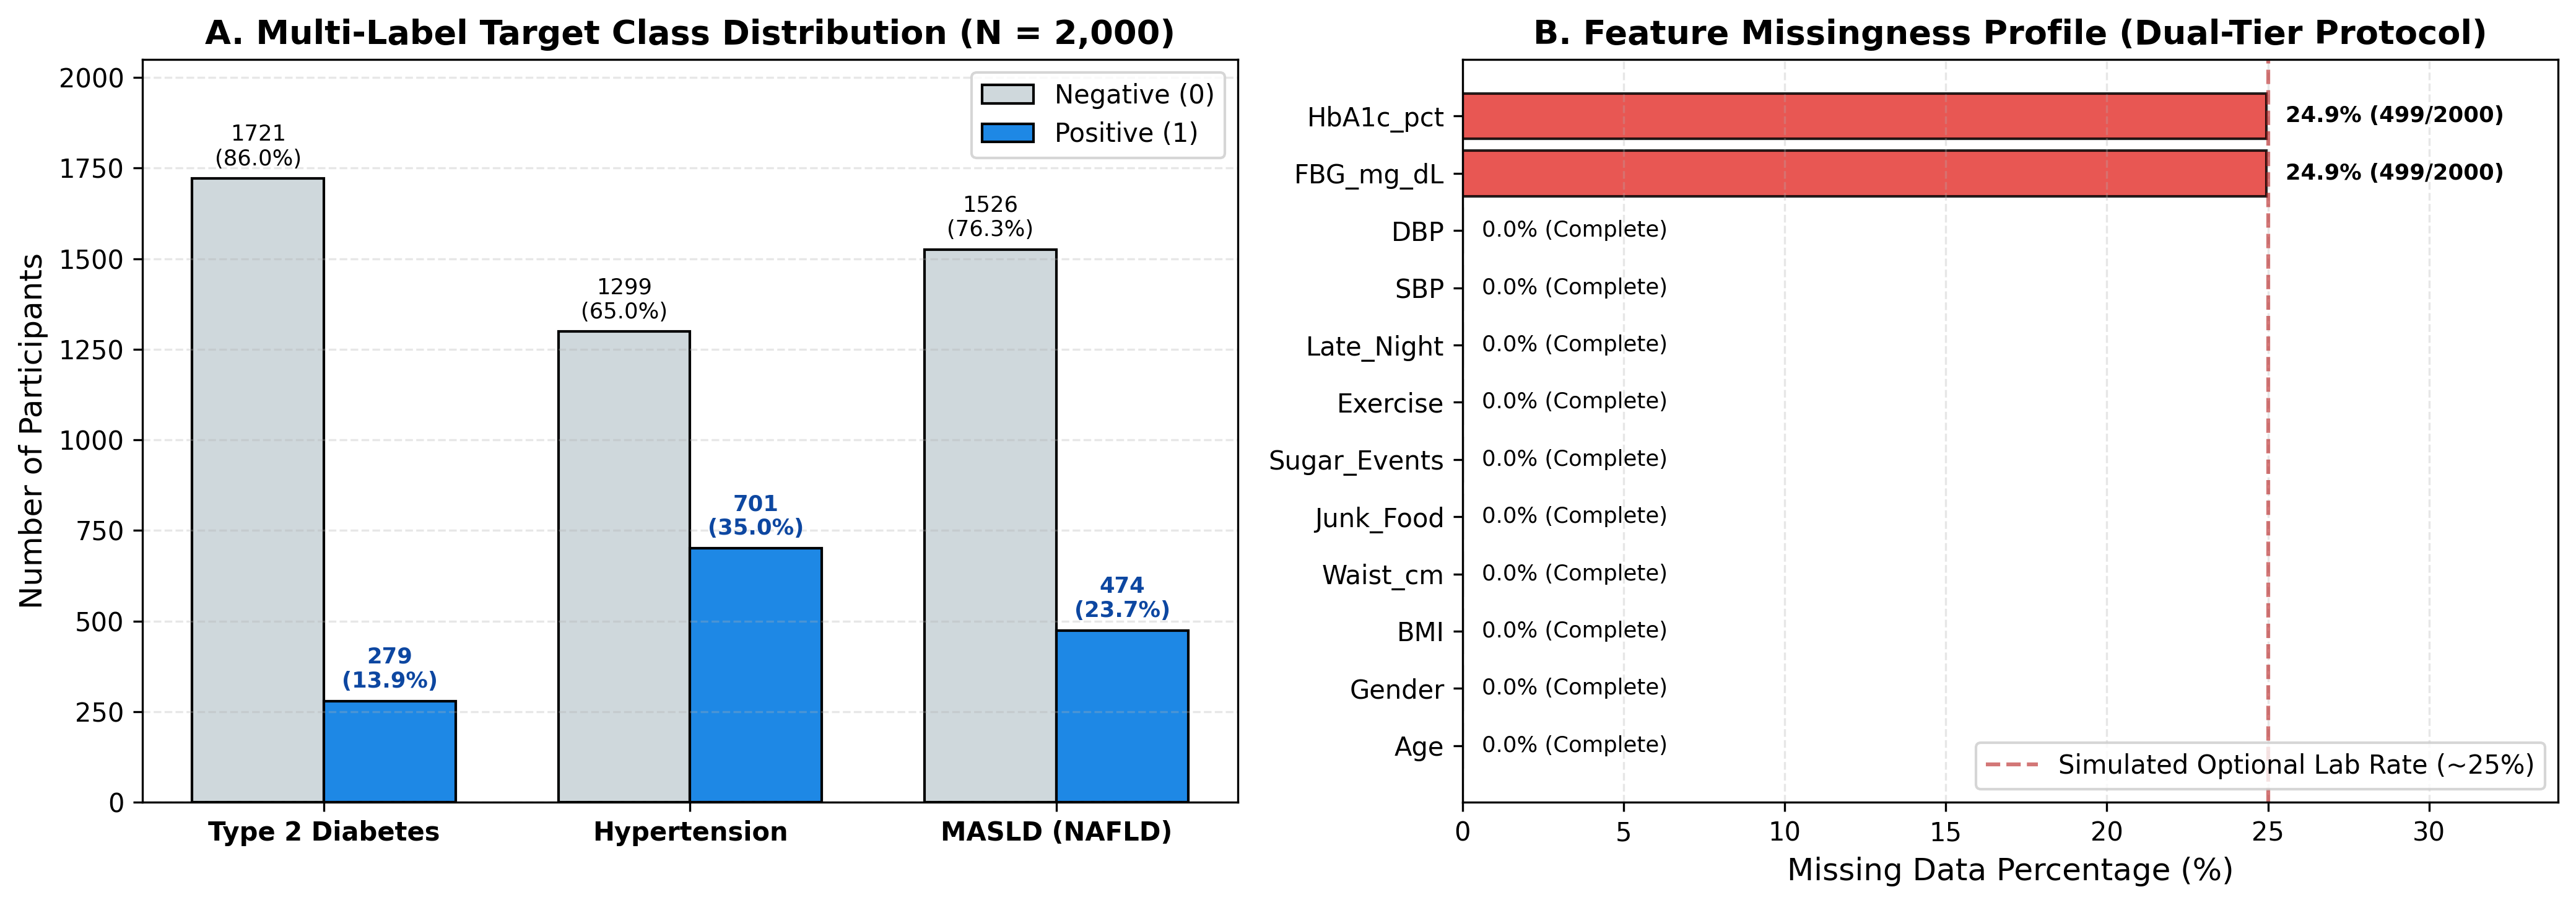

In [11]:
# ==============================================================================
# EDA FIGURE 1: Multi-Label Class Distribution & Missing Values Analysis
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.0), dpi=300)

targets = ['Type 2 Diabetes', 'Hypertension', 'MASLD (NAFLD)']
pos_counts = [df['Diabetes'].sum(), df['Hypertension'].sum(), df['NAFLD'].sum()]
neg_counts = [len(df) - c for c in pos_counts]

x = np.arange(len(targets))
width = 0.36
rects1 = ax1.bar(x - width/2, neg_counts, width, label='Negative (0)', color='#cfd8dc', edgecolor='black')
rects2 = ax1.bar(x + width/2, pos_counts, width, label='Positive (1)', color='#1e88e5', edgecolor='black')

ax1.set_title('A. Multi-Label Target Class Distribution (N = 2,000)', fontweight='bold')
ax1.set_ylabel('Number of Participants')
ax1.set_xticks(x)
ax1.set_xticklabels(targets, fontweight='bold')
ax1.set_ylim(0, 2050)
ax1.legend(loc='upper right', frameon=True)
ax1.grid(axis='y', linestyle='--', alpha=0.3)

for rect in rects1:
    h = rect.get_height()
    ax1.text(rect.get_x() + rect.get_width()/2., h + 25, f'{h}\n({h/20:.1f}%)', ha='center', va='bottom', fontsize=8.5)
for rect in rects2:
    h = rect.get_height()
    ax1.text(rect.get_x() + rect.get_width()/2., h + 25, f'{h}\n({h/20:.1f}%)', ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#0d47a1')

feat_names = ['Age', 'Gender', 'BMI', 'Waist_cm', 'Junk_Food', 'Sugar_Events', 'Exercise', 'Late_Night', 'SBP', 'DBP', 'FBG_mg_dL', 'HbA1c_pct']
miss_pcts = [df[c].isna().mean() * 100 for c in ['Age', 'Gender', 'BMI', 'Waist_cm', 'Junk_Food_Daily', 'Sugar_Events_Daily', 'Exercise_Days_Week', 'Late_Night_Eating_Week', 'SBP', 'DBP', 'FBG_mg_dL', 'HbA1c_pct']]
bar_colors = ['#e53935' if p > 0 else '#43a047' for p in miss_pcts]

bars = ax2.barh(feat_names, miss_pcts, color=bar_colors, edgecolor='black', alpha=0.85)
ax2.set_title('B. Feature Missingness Profile (Dual-Tier Protocol)', fontweight='bold')
ax2.set_xlabel('Missing Data Percentage (%)')
ax2.set_xlim(0, 34)
ax2.axvline(25.0, color='#b71c1c', linestyle='--', alpha=0.6, label='Simulated Optional Lab Rate (~25%)')
ax2.legend(loc='lower right', frameon=True)
ax2.grid(axis='x', linestyle='--', alpha=0.3)

for bar, p in zip(bars, miss_pcts):
    ax2.text(p + 0.6, bar.get_y() + bar.get_height()/2, f'{p:.1f}% ({int(round(p*20))}/2000)' if p > 0 else '0.0% (Complete)', va='center', ha='left', fontsize=8.5, fontweight='bold' if p > 0 else 'normal')

plt.tight_layout()
plt.savefig('Fig_EDA1_Class_Missingness.png', dpi=300, bbox_inches='tight')
plt.show()

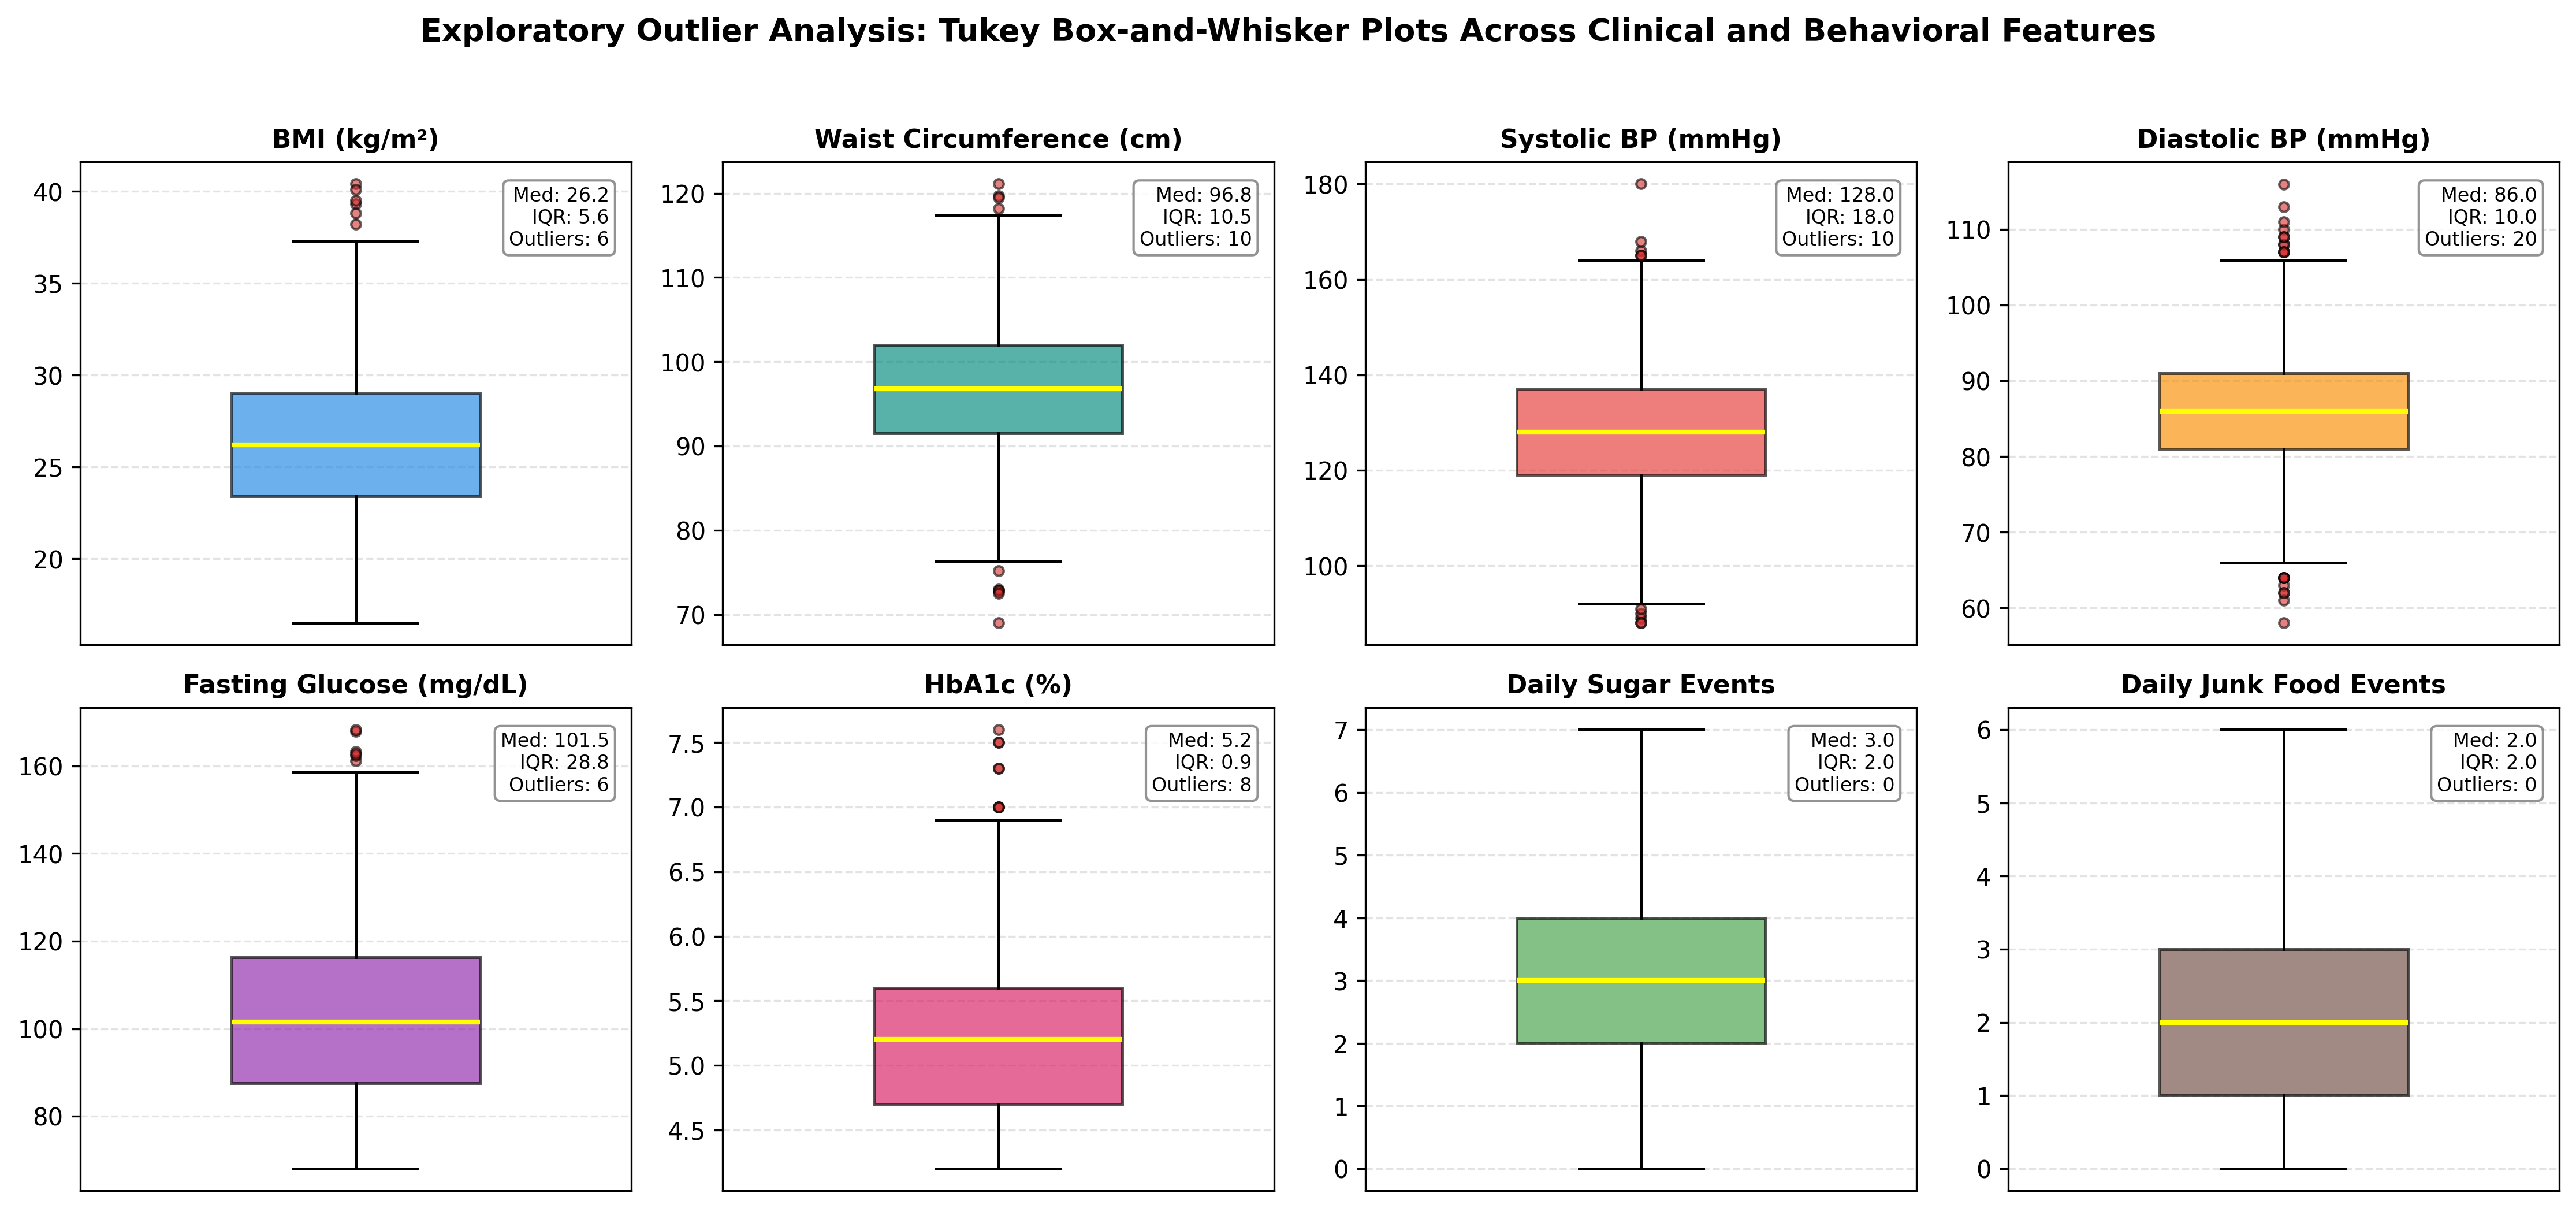

In [12]:
# ==============================================================================
# EDA FIGURE 2: Outlier Detection Using Box Plots (8 Key Continuous Features)
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 4, figsize=(15, 6.8), dpi=300)
box_features = [
    ('BMI', 'BMI (kg/m²)', '#1e88e5'),
    ('Waist_cm', 'Waist Circumference (cm)', '#00897b'),
    ('SBP', 'Systolic BP (mmHg)', '#e53935'),
    ('DBP', 'Diastolic BP (mmHg)', '#fb8c00'),
    ('FBG_mg_dL', 'Fasting Glucose (mg/dL)', '#8e24aa'),
    ('HbA1c_pct', 'HbA1c (%)', '#d81b60'),
    ('Sugar_Events_Daily', 'Daily Sugar Events', '#43a047'),
    ('Junk_Food_Daily', 'Daily Junk Food Events', '#6d4c41')
]

for idx, (col, label, color) in enumerate(box_features):
    r, c = idx // 4, idx % 4
    ax = axes[r, c]
    data = df[col].dropna()
    q25, q50, q75 = np.percentile(data, [25, 50, 75])
    iqr = q75 - q25
    outliers = data[(data < q25 - 1.5*iqr) | (data > q75 + 1.5*iqr)]

    bp = ax.boxplot(data, vert=True, patch_artist=True, widths=0.45,
                    boxprops=dict(facecolor=color, alpha=0.65, edgecolor='black', linewidth=1.2),
                    medianprops=dict(color='yellow', linewidth=2.0),
                    whiskerprops=dict(color='black', linewidth=1.2),
                    capprops=dict(color='black', linewidth=1.2),
                    flierprops=dict(marker='o', markerfacecolor='#d32f2f', markersize=4, alpha=0.6, markeredgecolor='black'))

    ax.set_title(label, fontweight='bold', fontsize=10.5)
    ax.set_xticks([])
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    ax.text(0.96, 0.95, f'Med: {q50:.1f}\nIQR: {iqr:.1f}\nOutliers: {len(outliers)}',
            transform=ax.transAxes, ha='right', va='top', fontsize=8,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85, edgecolor='gray'))

plt.suptitle('Exploratory Outlier Analysis: Tukey Box-and-Whisker Plots Across Clinical and Behavioral Features', fontweight='bold', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('Fig_EDA2_Outlier_Boxplots.png', dpi=300, bbox_inches='tight')
plt.show()

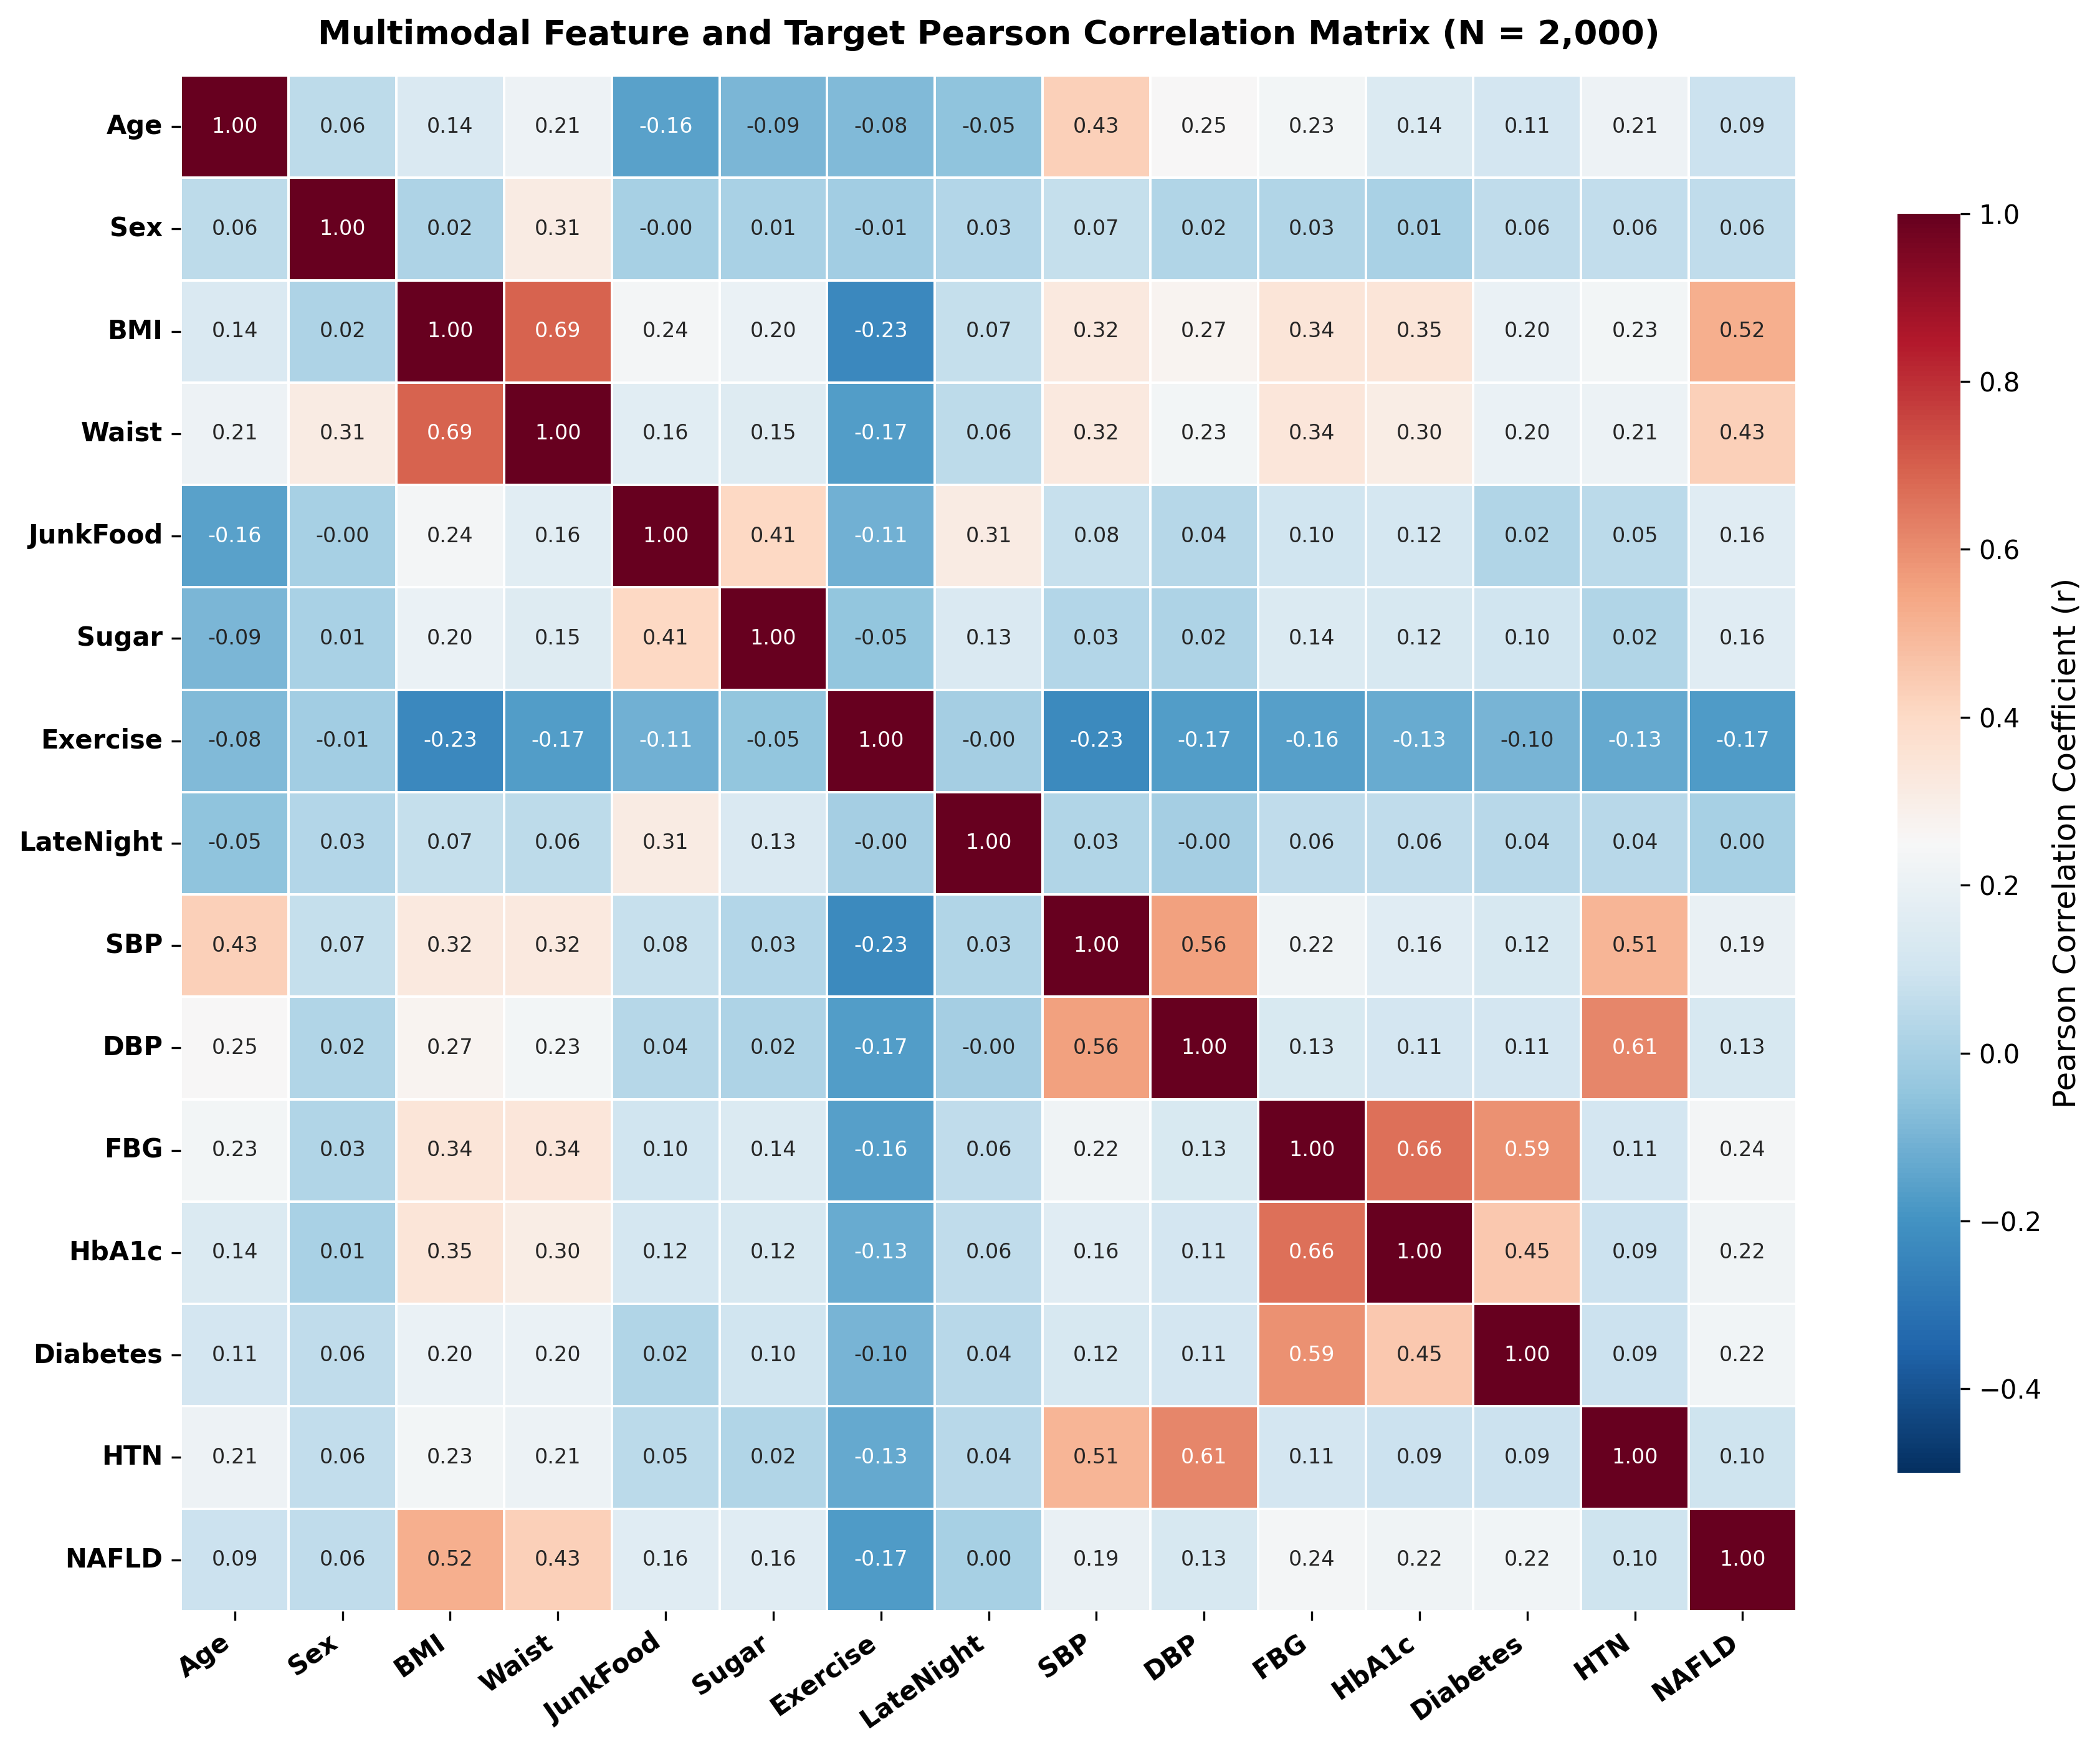

In [14]:
# ==============================================================================
# EDA FIGURE 3: Multimodal Pearson Correlation Matrix Heatmap (15 x 15)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 9.5), dpi=300)
corr_cols = ['Age', 'Gender', 'BMI', 'Waist_cm', 'Junk_Food_Daily', 'Sugar_Events_Daily',
             'Exercise_Days_Week', 'Late_Night_Eating_Week', 'SBP', 'DBP', 'FBG_mg_dL', 'HbA1c_pct',
             'Diabetes', 'Hypertension', 'NAFLD']
short_labels = ['Age', 'Sex', 'BMI', 'Waist', 'JunkFood', 'Sugar', 'Exercise', 'LateNight',
                'SBP', 'DBP', 'FBG', 'HbA1c', 'Diabetes', 'HTN', 'NAFLD']

corr_matrix = df[corr_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-0.5, vmax=1.0,
            xticklabels=short_labels, yticklabels=short_labels,
            cbar_kws={'label': 'Pearson Correlation Coefficient (r)', 'shrink': 0.82},
            linewidths=0.5, linecolor='white', annot_kws={'size': 8})

plt.title('Multimodal Feature and Target Pearson Correlation Matrix (N = 2,000)', fontweight='bold', fontsize=13, pad=12)
plt.xticks(rotation=35, ha='right', fontweight='bold')
plt.yticks(rotation=0, fontweight='bold')
plt.tight_layout()
plt.savefig('Fig_EDA3_Correlation_Matrix.png', dpi=300, bbox_inches='tight')
plt.show()